## 1. Import libraries

In [1]:
import os, time, random, pathlib, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Dataset collection and problem identification

### Problem statement
Pneumonia is a lung infection. This project investigates whether a deep-learning image-classification model can learn patterns in chest X-ray images labelled as `NORMAL` or `PNEUMONIA`.

### Dataset information
- Source: Kaggle – Chest X-Ray Images (Pneumonia).
- Format: JPEG images.
- Classes: `NORMAL` and `PNEUMONIA`.
- The images have different original dimensions, so they are resized to a common size.
- The dataset is class-imbalanced; class weights are used during training.

**Dataset link:** https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

In [2]:
# Find the dataset folder in Kaggle input.
# If automatic detection fails, manually set DATASET_ROOT to the folder
# that directly contains train/, test/ and val/.

possible_roots = [
    pathlib.Path("/kaggle/input/chest-xray-pneumonia/chest_xray"),
    pathlib.Path("/kaggle/input/chest-xray-pneumonia"),
    pathlib.Path("/kaggle/input/chest-xray-images-pneumonia/chest_xray"),
    pathlib.Path("/kaggle/input/chest-xray-images-pneumonia"),
]

DATASET_ROOT = None
for candidate in possible_roots:
    if (candidate / "train").exists() and (candidate / "test").exists():
        DATASET_ROOT = candidate
        break

if DATASET_ROOT is None:
    # Search one level below /kaggle/input
    for candidate in pathlib.Path("/kaggle/input").glob("**/chest_xray"):
        if (candidate / "train").exists() and (candidate / "test").exists():
            DATASET_ROOT = candidate
            break

if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Dataset not found. Add the Kaggle dataset using Add Input, "
        "then set DATASET_ROOT to the folder containing train/, test/ and val/."
    )

print("Dataset root:", DATASET_ROOT)
print("Folders:", [p.name for p in DATASET_ROOT.iterdir() if p.is_dir()])

Dataset root: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
Folders: ['__MACOSX', 'chest_xray', 'test', 'train', 'val']


## 3. Dataset cleaning and preprocessing

In [3]:
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def collect_image_paths(split_dir):
    rows = []
    for label, class_name in enumerate(CLASS_NAMES):
        class_dir = pathlib.Path(split_dir) / class_name
        if not class_dir.exists():
            raise FileNotFoundError(f"Missing class folder: {class_dir}")
        for path in class_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({"path": str(path), "label": label, "class_name": class_name})
    return rows

# Keep the official test set untouched.
train_rows = collect_image_paths(DATASET_ROOT / "train")
val_folder = DATASET_ROOT / "val"
if val_folder.exists():
    train_rows += collect_image_paths(val_folder)
test_rows = collect_image_paths(DATASET_ROOT / "test")

print("Training + original validation files:", len(train_rows))
print("Official test files:", len(test_rows))

Training + original validation files: 5232
Official test files: 624


In [4]:
# Verify that files can be opened; remove corrupt/unreadable images.
def remove_corrupt_images(rows):
    valid_rows = []
    bad_paths = []
    for row in rows:
        try:
            with Image.open(row["path"]) as img:
                img.verify()
            valid_rows.append(row)
        except (UnidentifiedImageError, OSError, ValueError):
            bad_paths.append(row["path"])
    return valid_rows, bad_paths

train_rows, bad_train = remove_corrupt_images(train_rows)
test_rows, bad_test = remove_corrupt_images(test_rows)

print("Valid train/validation pool:", len(train_rows))
print("Valid test images:", len(test_rows))
print("Corrupt files removed:", len(bad_train) + len(bad_test))

Valid train/validation pool: 5232
Valid test images: 624
Corrupt files removed: 0


In [5]:
# Stratified split: 80% training and 20% validation.
train_df = pd.DataFrame(train_rows)
test_df = pd.DataFrame(test_rows)

train_df, valid_df = train_test_split(
    train_df, test_size=0.20, random_state=SEED,
    stratify=train_df["label"]
)
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df), "Validation:", len(valid_df), "Test:", len(test_df))
print("Class mapping:", {name: i for i, name in enumerate(CLASS_NAMES)})

Train: 4185 Validation: 1047 Test: 624
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


## 4. Exploratory Data Analysis (EDA)

,Split,Class,Images
0,Train,NORMAL,1079
1,Train,PNEUMONIA,3106
2,Validation,NORMAL,270
3,Validation,PNEUMONIA,777
4,Test,NORMAL,234
5,Test,PNEUMONIA,390


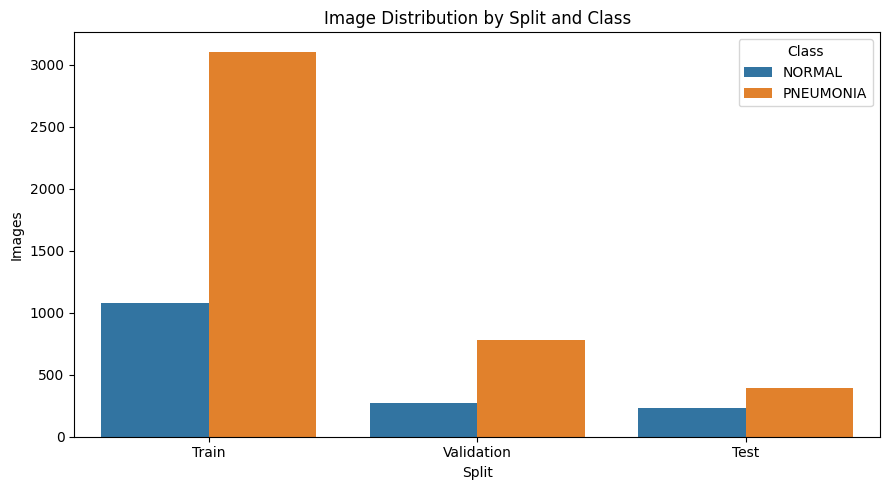

In [6]:
# Class distribution across all splits.
distribution = []
for split_name, frame in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]:
    counts = frame["class_name"].value_counts()
    for class_name in CLASS_NAMES:
        distribution.append({
            "Split": split_name,
            "Class": class_name,
            "Images": int(counts.get(class_name, 0))
        })

distribution_df = pd.DataFrame(distribution)
display(distribution_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=distribution_df, x="Split", y="Images", hue="Class")
plt.title("Image Distribution by Split and Class")
plt.tight_layout()
plt.show()

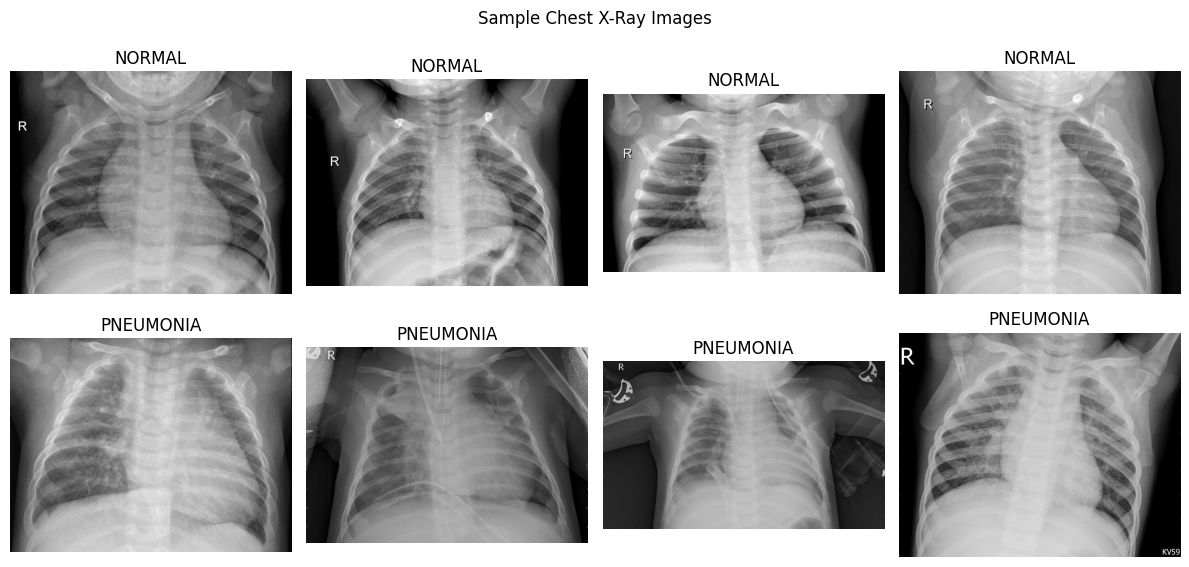

In [7]:
# Show sample images from both categories.
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, class_name in enumerate(CLASS_NAMES):
    samples = train_df[train_df["class_name"] == class_name].sample(
        min(4, (train_df["class_name"] == class_name).sum()), random_state=SEED
    )
    for col, (_, item) in enumerate(samples.iterrows()):
        img = Image.open(item["path"]).convert("RGB")
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")
    for col in range(len(samples), 4):
        axes[row, col].axis("off")
plt.suptitle("Sample Chest X-Ray Images")
plt.tight_layout()
plt.show()

,Width,Height
count,300.000000,300.000000
mean,1316.843333,963.546667
std,344.152440,377.058596
min,453.000000,182.000000
25%,1064.000000,680.000000
50%,1276.000000,868.000000
75%,1584.000000,1218.000000
max,2434.000000,2376.000000


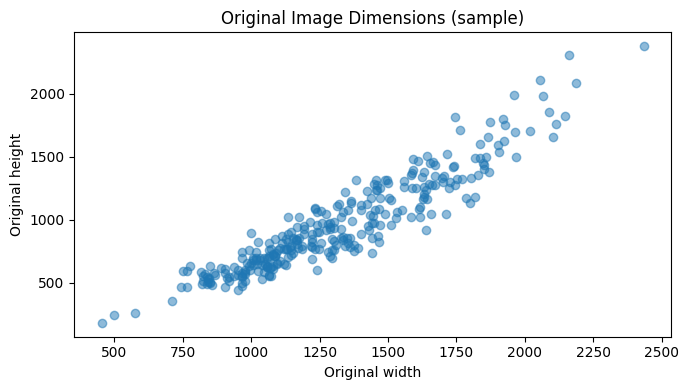

In [8]:
# Original image dimensions (sampled to keep EDA quick).
sample_paths = train_df["path"].sample(min(300, len(train_df)), random_state=SEED)
dimensions = []
for path in sample_paths:
    with Image.open(path) as img:
        dimensions.append(img.size)

dimension_df = pd.DataFrame(dimensions, columns=["Width", "Height"])
display(dimension_df.describe())

plt.figure(figsize=(7, 4))
plt.scatter(dimension_df["Width"], dimension_df["Height"], alpha=0.5)
plt.xlabel("Original width")
plt.ylabel("Original height")
plt.title("Original Image Dimensions (sample)")
plt.tight_layout()
plt.show()

## 5. Feature preparation, visualization and train-test splitting

For image data, selecting columns with methods such as SelectKBest is not appropriate because pixels are spatially connected. The CNN architectures learn image features automatically (for example, edges, textures and larger patterns). The notebook visualizes sample images and later uses Grad-CAM to highlight image regions that influence one model's prediction. Grad-CAM is an explanation aid, not proof of clinical reasoning.

In [9]:
IMG_SIZE = 160
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def decode_resize(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)  # keep pixel range 0..255
    return image, tf.cast(label, tf.float32)

def make_dataset(frame, training=False):
    paths = frame["path"].values
    labels = frame["label"].values.astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
valid_ds = make_dataset(valid_df)
test_ds = make_dataset(test_df)

# Class weights to reduce the effect of class imbalance.
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=train_df["label"].values
)
CLASS_WEIGHTS = {int(i): float(w) for i, w in zip(classes, weights)}
print("Class weights:", CLASS_WEIGHTS)

# Confirm batch shape.
for image_batch, label_batch in train_ds.take(1):
    print("Image batch:", image_batch.shape, "Label batch:", label_batch.shape)

Class weights: {0: 1.9392956441149212, 1: 0.6736960721184804}
Image batch: (32, 160, 160, 3) Label batch: (32,)


## 6. Build the seven deep-learning models

The six pretrained architectures use ImageNet weights as feature extractors, with their convolutional base initially frozen. The final classification layers are trained on this dataset. The Custom CNN is trained from scratch. The models are trained independently using the same training and validation partitions.

In [10]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.08),
], name="data_augmentation")

def build_custom_cnn():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1./255)(inputs)
    x = augmentation(x)
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.20)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="Custom_CNN")

def build_transfer_model(model_name):
    app_map = {
        "MobileNetV2": (keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
        "ResNet50": (keras.applications.ResNet50, keras.applications.resnet.preprocess_input),
        "EfficientNetB0": (keras.applications.EfficientNetB0, None),
        "DenseNet121": (keras.applications.DenseNet121, keras.applications.densenet.preprocess_input),
        "VGG16": (keras.applications.VGG16, keras.applications.vgg16.preprocess_input),
        "InceptionV3": (keras.applications.InceptionV3, keras.applications.inception_v3.preprocess_input),
    }
    app_class, preprocess = app_map[model_name]
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(inputs)
    if preprocess is not None:
        x = layers.Lambda(preprocess, name="application_preprocessing")(x)
    base = app_class(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name=model_name)
    return model

MODEL_NAMES = [
    "Custom_CNN", "MobileNetV2", "ResNet50", "EfficientNetB0",
    "DenseNet121", "VGG16", "InceptionV3"
]

def create_model(name):
    if name == "Custom_CNN":
        return build_custom_cnn()
    return build_transfer_model(name)

## 7. Train and evaluate all seven models

In [11]:
# Default training configuration. Increase EPOCHS if time and GPU resources allow.
EPOCHS = 3
LEARNING_RATE = 1e-3

results = []
histories = {}
trained_models = {}

def evaluate_model(model, dataset):
    y_true = np.concatenate([y.numpy().ravel() for _, y in dataset]).astype(int)
    y_prob = model.predict(dataset, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

for model_name in MODEL_NAMES:
    print("\n" + "="*65)
    print("Training:", model_name)
    model = create_model(model_name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall")]
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6
        )
    ]

    start_train = time.time()
    history = model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=EPOCHS,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks,
        verbose=1
    )
    train_seconds = time.time() - start_train

    start_eval = time.time()
    metrics = evaluate_model(model, test_ds)
    eval_seconds = time.time() - start_eval
    test_count = len(test_df)
    inference_ms = (eval_seconds / max(test_count, 1)) * 1000

    results.append({
        "Model": model_name,
        "Accuracy": metrics["accuracy"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1-score": metrics["f1"],
        "ROC-AUC": metrics["roc_auc"],
        "Parameters": model.count_params(),
        "Training_Time_sec": train_seconds,
        "Inference_ms_per_image": inference_ms
    })
    histories[model_name] = history.history
    trained_models[model_name] = model

    # Save the trained model in Kaggle's working directory.
    model.save(f"/kaggle/working/{model_name}.keras")

    # Store predictions for later comparison and confusion matrices.
    np.savez(
        f"/kaggle/working/{model_name}_predictions.npz",
        y_true=metrics["y_true"], y_pred=metrics["y_pred"],
        y_prob=metrics["y_prob"]
    )
    print("Finished:", model_name)


Training: Custom_CNN
Epoch 1/3


E0000 00:00:1794219205.085589      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Custom_CNN_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


131/131 ━━━━━━━━━━━━━━━━━━━━ 57s 365ms/step - accuracy: 0.8335 - loss: 0.3520 - precision: 0.9575 - recall: 0.8117 - val_accuracy: 0.7421 - val_loss: 0.8068 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step - accuracy: 0.8805 - loss: 0.2906 - precision: 0.9704 - recall: 0.8654 - val_accuracy: 0.7421 - val_loss: 2.0254 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - accuracy: 0.8949 - loss: 0.2453 - precision: 0.9754 - recall: 0.8806 - val_accuracy: 0.7421 - val_loss: 3.8293 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Finished: Custom_CNN

Training: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 22s 127ms/step - accuracy: 0.8808 - loss: 0.2788 - precision: 0.9591 - recall: 0.8767 - val_accuracy: 0.8329 - val_loss: 0.3941 - val_precision: 0.9934 - val_recall: 

E0000 00:00:1794219430.504497      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


131/131 ━━━━━━━━━━━━━━━━━━━━ 26s 136ms/step - accuracy: 0.8760 - loss: 0.2607 - precision: 0.9625 - recall: 0.8667 - val_accuracy: 0.9054 - val_loss: 0.2133 - val_precision: 0.9885 - val_recall: 0.8829 - learning_rate: 0.0010
Epoch 2/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - accuracy: 0.9116 - loss: 0.2090 - precision: 0.9740 - recall: 0.9050 - val_accuracy: 0.8634 - val_loss: 0.3570 - val_precision: 0.9984 - val_recall: 0.8172 - learning_rate: 0.0010
Epoch 3/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - accuracy: 0.9200 - loss: 0.1792 - precision: 0.9766 - recall: 0.9140 - val_accuracy: 0.8988 - val_loss: 0.2690 - val_precision: 0.9970 - val_recall: 0.8662 - learning_rate: 5.0000e-04
Finished: EfficientNetB0

Training: DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
131/131 ━━━━━━━━━━━━━━━━━━━━ 32s 157ms/step - accuracy: 0.8389 - loss: 0.3869 - precision: 0.9403 - recall: 0.8361 - val_accuracy: 0.8510 - val_loss: 0.3340 - val_precision: 0.9905 - val_re

## 8. Performance evaluation and model comparison

In [12]:
results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1-score": "{:.4f}", "ROC-AUC": "{:.4f}",
    "Training_Time_sec": "{:.1f}", "Inference_ms_per_image": "{:.2f}"
}))

results_df.to_csv("/kaggle/working/model_comparison.csv", index=False)
best_model_name = results_df.iloc[0]["Model"]
print("Best model by test F1-score:", best_model_name)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Parameters,Training_Time_sec,Inference_ms_per_image
1,MobileNetV2,0.8862,0.9370,0.8769,0.9060,0.9510,2422081,51.9,8.04
4,DenseNet121,0.8670,0.8847,0.9051,0.8948,0.9407,7168833,64.6,15.97
2,ResNet50,0.8590,0.8401,0.9564,0.8945,0.9512,23850113,55.3,10.43
5,VGG16,0.8542,0.8375,0.9513,0.8908,0.9324,14780481,49.2,6.31
3,EfficientNetB0,0.8478,0.8345,0.9436,0.8857,0.9418,4213668,56.8,10.96
6,InceptionV3,0.8510,0.8898,0.8692,0.8794,0.9145,22065185,56.9,11.67
0,Custom_CNN,0.6250,0.6250,1.0000,0.7692,0.8421,110785,87.2,12.01


Best model by test F1-score: MobileNetV2


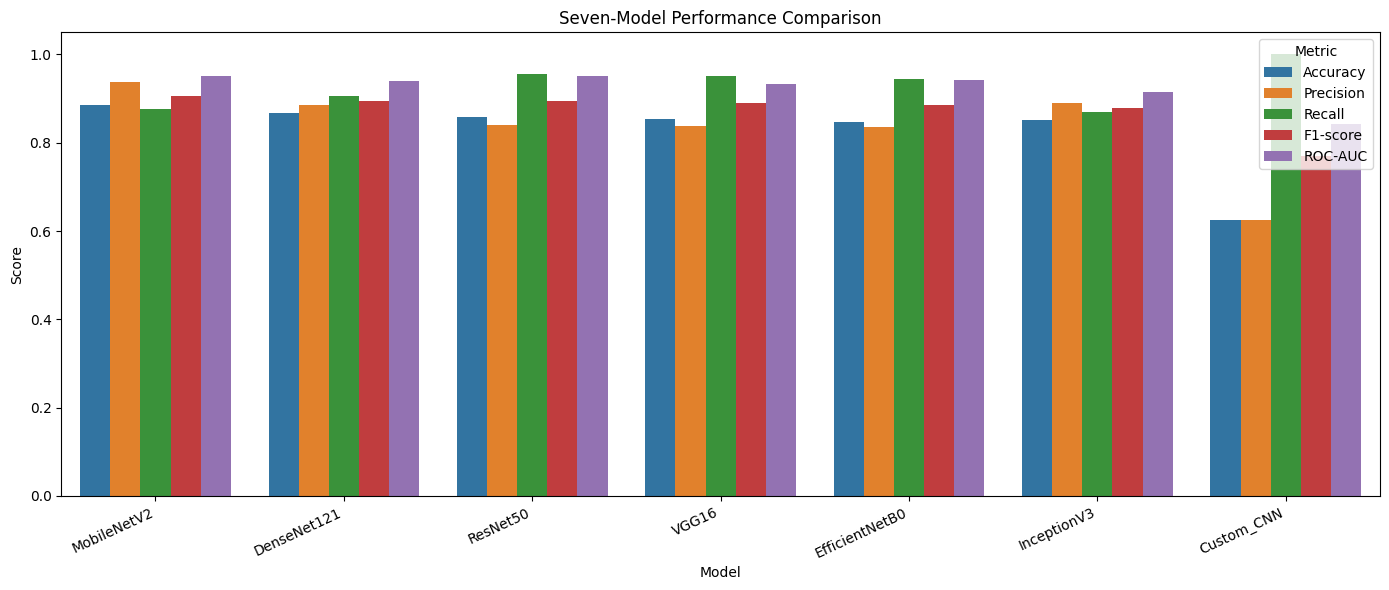

In [13]:
# Compare key classification metrics.
metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
plot_df = results_df.melt(
    id_vars="Model", value_vars=metric_columns,
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.title("Seven-Model Performance Comparison")
plt.tight_layout()
plt.show()

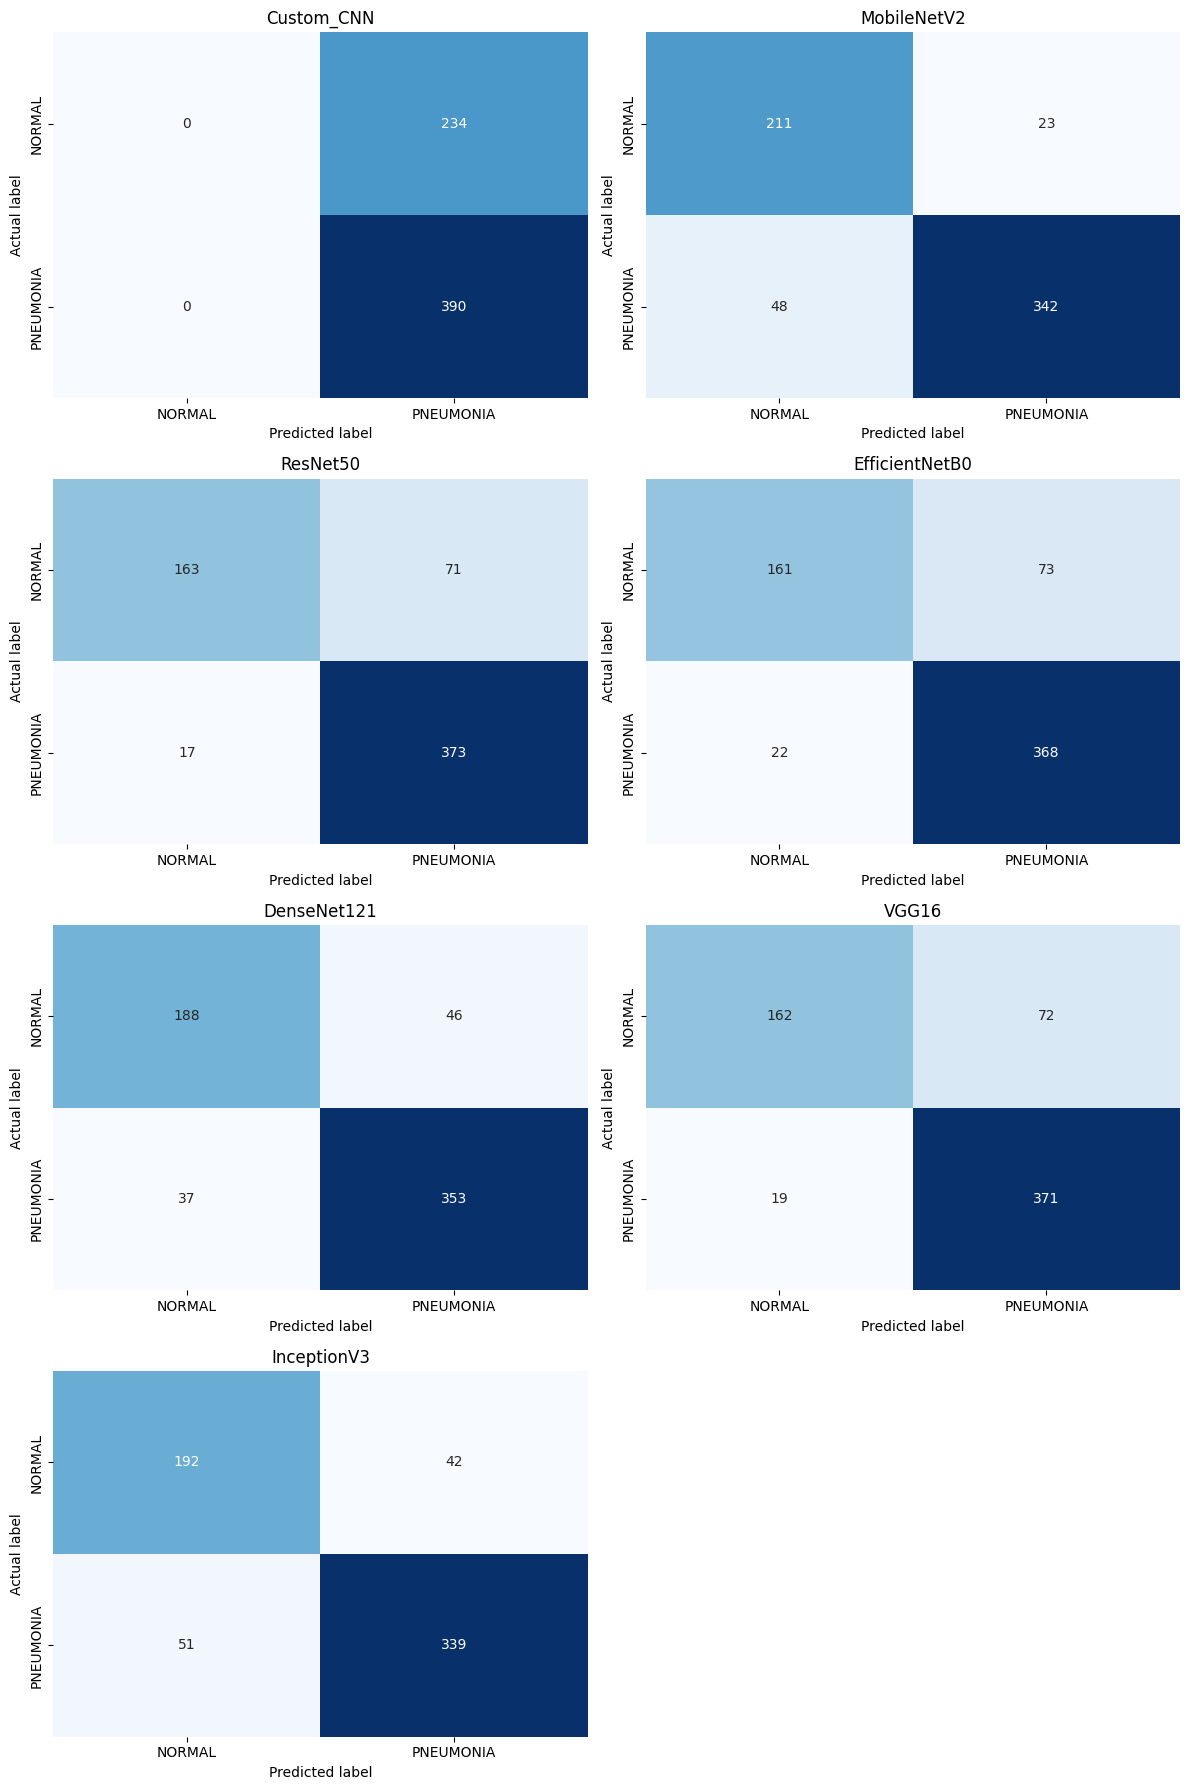

In [14]:
# Confusion matrix for every model.
fig, axes = plt.subplots(4, 2, figsize=(12, 18))
axes = axes.ravel()

for idx, model_name in enumerate(MODEL_NAMES):
    pred = np.load(f"/kaggle/working/{model_name}_predictions.npz")
    cm = confusion_matrix(pred["y_true"], pred["y_pred"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[idx]
    )
    axes[idx].set_title(model_name)
    axes[idx].set_xlabel("Predicted label")
    axes[idx].set_ylabel("Actual label")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

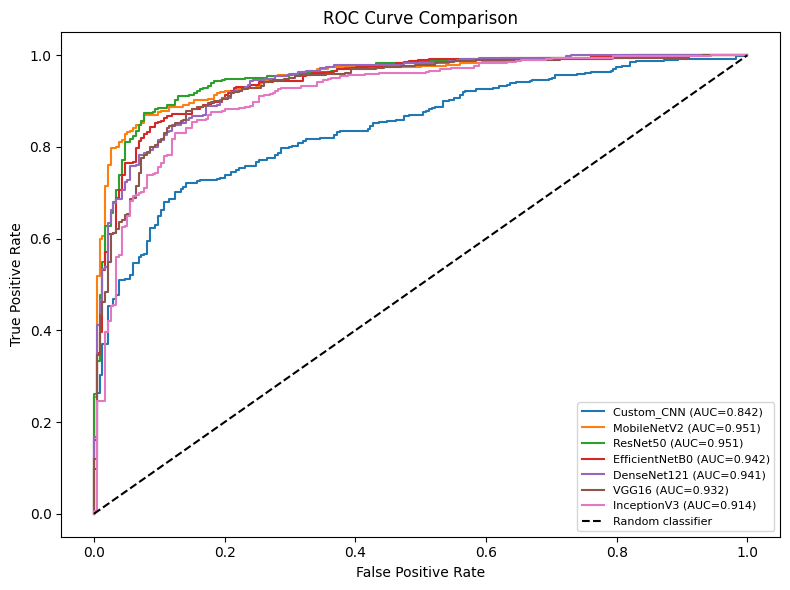

In [15]:
# ROC curves for all seven models.
plt.figure(figsize=(8, 6))
for model_name in MODEL_NAMES:
    pred = np.load(f"/kaggle/working/{model_name}_predictions.npz")
    fpr, tpr, _ = roc_curve(pred["y_true"], pred["y_prob"])
    auc_value = roc_auc_score(pred["y_true"], pred["y_prob"])
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

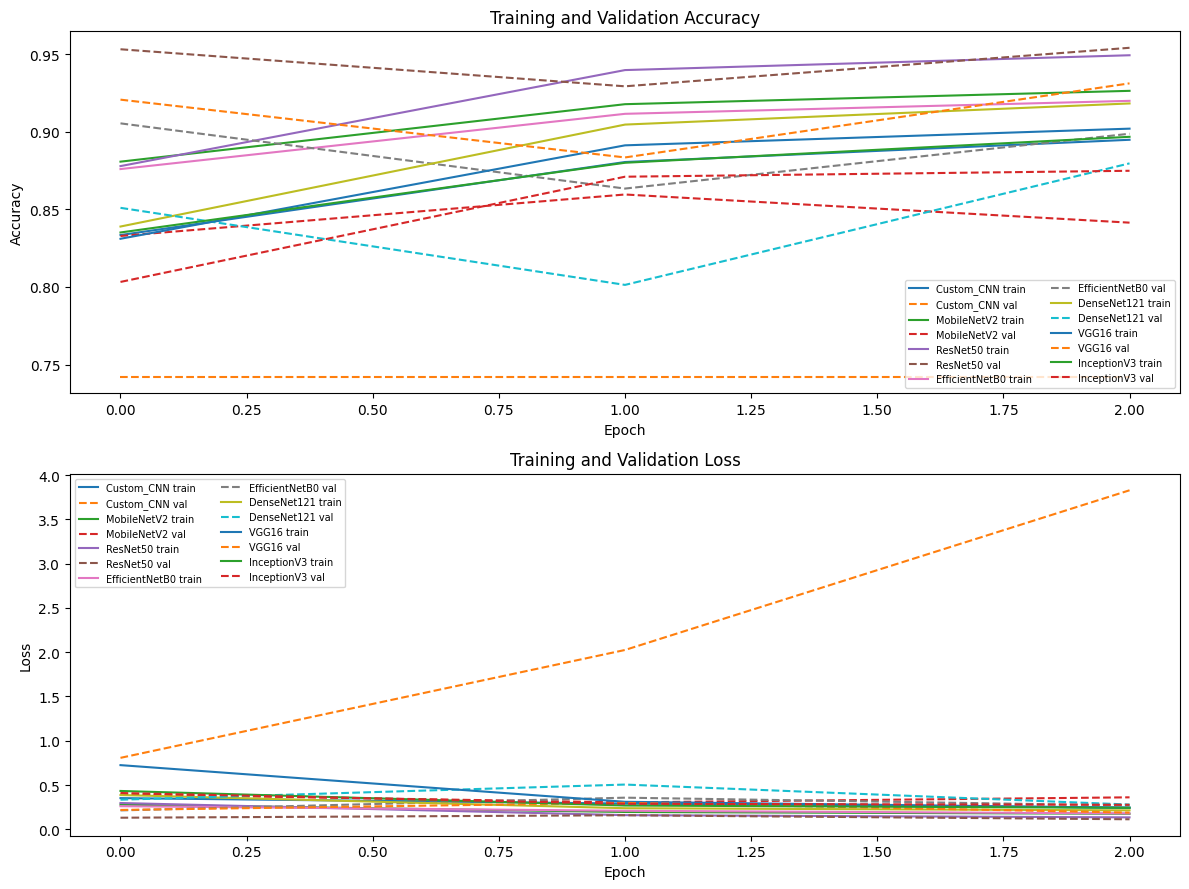

In [16]:
# Training and validation accuracy/loss curves.
fig, axes = plt.subplots(2, 1, figsize=(12, 9))
for model_name, history in histories.items():
    axes[0].plot(history["accuracy"], label=f"{model_name} train")
    axes[0].plot(history["val_accuracy"], linestyle="--", label=f"{model_name} val")
    axes[1].plot(history["loss"], label=f"{model_name} train")
    axes[1].plot(history["val_loss"], linestyle="--", label=f"{model_name} val")

axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(fontsize=7, ncol=2)
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 9. Classification report and result interpretation

In [17]:
for model_name in MODEL_NAMES:
    pred = np.load(f"/kaggle/working/{model_name}_predictions.npz")
    print("\n", "="*60)
    print("Classification report:", model_name)
    print(classification_report(
        pred["y_true"], pred["y_pred"],
        target_names=CLASS_NAMES, zero_division=0
    ))


Classification report: Custom_CNN
              precision    recall  f1-score   support

      NORMAL       0.00      0.00      0.00       234
   PNEUMONIA       0.62      1.00      0.77       390

    accuracy                           0.62       624
   macro avg       0.31      0.50      0.38       624
weighted avg       0.39      0.62      0.48       624


Classification report: MobileNetV2
              precision    recall  f1-score   support

      NORMAL       0.81      0.90      0.86       234
   PNEUMONIA       0.94      0.88      0.91       390

    accuracy                           0.89       624
   macro avg       0.88      0.89      0.88       624
weighted avg       0.89      0.89      0.89       624


Classification report: ResNet50
              precision    recall  f1-score   support

      NORMAL       0.91      0.70      0.79       234
   PNEUMONIA       0.84      0.96      0.89       390

    accuracy                           0.86       624
   macro avg       0.87 

In [18]:
# Automatically generate a result interpretation from the measured values.
best_row = results_df.iloc[0]
print("RESULT INTERPRETATION")
print("---------------------")
print(f"Best model by F1-score: {best_row['Model']}")
print(f"Accuracy:  {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall:    {best_row['Recall']:.4f}")
print(f"F1-score:  {best_row['F1-score']:.4f}")
print(f"ROC-AUC:   {best_row['ROC-AUC']:.4f}")
print("\nInterpretation:")
print("- Accuracy measures the proportion of all correct predictions.")
print("- Precision measures how many predicted pneumonia cases were correct.")
print("- Recall measures how many actual pneumonia cases were detected.")
print("- F1-score balances precision and recall.")
print("- ROC-AUC measures how well the model separates the two classes.")
print("\nUse the comparison table and confusion matrices to discuss false negatives "
      "and false positives. In a medical context, false negatives are especially "
      "important to examine.")

RESULT INTERPRETATION
---------------------
Best model by F1-score: MobileNetV2
Accuracy:  0.8862
Precision: 0.9370
Recall:    0.8769
F1-score:  0.9060
ROC-AUC:   0.9510

Interpretation:
- Accuracy measures the proportion of all correct predictions.
- Precision measures how many predicted pneumonia cases were correct.
- Recall measures how many actual pneumonia cases were detected.
- F1-score balances precision and recall.
- ROC-AUC measures how well the model separates the two classes.

Use the comparison table and confusion matrices to discuss false negatives and false positives. In a medical context, false negatives are especially important to examine.


## 10. Feature visualization using Grad-CAM

In [24]:
print(best_model_name)
print(best_model.input_shape)
print(best_model.output_shape)

MobileNetV2
(None, 160, 160, 3)
(None, 1)


## 11. Test a single image

In [21]:
def predict_xray(image_path, model=best_model):
    image = Image.open(image_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    array = np.asarray(image).astype("float32")
    probability = float(model.predict(array[np.newaxis, ...], verbose=0)[0][0])
    predicted_class = "PNEUMONIA" if probability >= 0.5 else "NORMAL"
    print("Model output class:", predicted_class)
    print(f"Model probability for PNEUMONIA: {probability:.4f}")
    print("Educational demonstration only — not a medical diagnosis.")

# Example: use a test image path.
example_path = test_df.iloc[0]["path"]
predict_xray(example_path)

Model output class: NORMAL
Model probability for PNEUMONIA: 0.0564
Educational demonstration only — not a medical diagnosis.
